# Proyecto final - Prediccion de rendimiento multi-core de CPUs + MLOps
Elias Rodriguez

La idea (ver Avance 1): con las especificaciones de un procesador (nucleos, TDP, socket, tipo, anio...) predecir su rendimiento multi-core (cpuMark de PassMark) sin tener que correr el benchmark.

Ademas de el modelo arme la parte de MLOps:
- datos fresh: el pipeline baja la ultima version del dataset de kaggle y si no cambio no reentrena
- MLflow en local: **metadatos en sqlite** (`mlflow.db`) y **artifacts en carpeta aparte** (`mlartifacts/`)
- experimentos con nombres leibles, data version, tags, runs anidados y registro de modelos con alias `produccion`
- prediccion batch y online (API), monitoreo de latencia/salud, calidad de datos, KPI de negocio
- drift: data drift, label drift y concept drift
- simulacion de como se veria en produccion anio por anio

Todo el codigo esta en `src/`, este notebook nomas llama a esas funciones y lee lo que quedo en mlflow y en `reportes/`.

## Paso 0 - setup

In [1]:
import os, sys, json, sqlite3, warnings
warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import mlflow
from mlflow.tracking import MlflowClient
from IPython.display import Image, display
from src import config, datos, calidad, modelos, monitoreo

mlflow.set_tracking_uri(config.TRACKING_URI)
cliente = MlflowClient()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("tracking (metadatos):", config.TRACKING_URI)
print("artifacts           :", config.ARTIFACTS)

tracking (metadatos): sqlite:////mnt/c/Users/EliasRodriguez/Documents/GitHub/SingleCycle_Arch/myFiles/Masters/Automatic_Learn/Proj/mlflow.db
artifacts           : /mnt/c/Users/EliasRodriguez/Documents/GitHub/SingleCycle_Arch/myFiles/Masters/Automatic_Learn/Proj/mlartifacts


## Paso 1 - datos fresh
`datos.descargar()` baja la ultima version de kaggle (`alanjo/cpu-benchmarks`), saca la version y un hash md5 del archivo. Con eso el pipeline sabe si ya entreno con esos datos o no.

In [2]:
info = datos.descargar()
df = datos.cargar(info["ruta"])
print(info)
print(df.shape)
df.head()

{'ruta': '/mnt/c/Users/EliasRodriguez/Documents/GitHub/SingleCycle_Arch/myFiles/Masters/Automatic_Learn/Proj/datos/raw/v26/CPU_benchmark_v4.csv', 'version': '26', 'hash': 'ecc4a219587e'}
(3825, 12)


,cpuName,price,cpuMark,cpuValue,threadMark,threadValue,TDP,powerPerf,cores,testDate,socket,category
0,AMD Ryzen Threadripper PRO 5995WX,NaN,108822,NaN,3330,NaN,280.0,388.65,64,2022,sWRX8,Desktop
1,AMD EPYC 7763,7299.99,88338,12.10,2635,0.36,280.0,315.49,64,2021,SP3,Server
2,AMD EPYC 7J13,NaN,86006,NaN,2387,NaN,NaN,NaN,64,2021,unknown,Server
3,AMD EPYC 7713,7060.00,85861,12.16,2727,0.39,225.0,381.6,64,2021,SP3,Server
4,AMD Ryzen Threadripper PRO 3995WX,6807.98,83971,12.33,2626,0.39,280.0,299.9,64,2020,sWRX8,Desktop


In [3]:
# el ultimo pipeline que corrio (se corre con cron, ver correr_pipeline.sh)
print(json.dumps(json.load(open("reportes/ultimo_pipeline.json")), indent=2))

{
  "estado": "ok",
  "ruta": "/mnt/c/Users/EliasRodriguez/Documents/GitHub/SingleCycle_Arch/myFiles/Masters/Automatic_Learn/Proj/datos/raw/v26/CPU_benchmark_v4.csv",
  "version": "26",
  "hash": "ecc4a219587e",
  "version_techpowerup": "2",
  "version_pc_build": "hf-main",
  "cobertura_externos": "38%",
  "mejor_modelo": "hibrido_reciente",
  "mejor_mae": 804.1488842759167,
  "duracion_seg": 237.881146,
  "fecha": "2026-11-09T01:30:04"
}


Si se vuelve a correr `python -m src.pipeline` y kaggle no cambio el archivo, sale `estado: sin cambios` y no reentrena (se puede forzar con `--forzar`).

## Paso 2 - calidad de datos
Antes de entrenar se revisa esquema, filas, nulos en el objetivo (esto es critico, si falla no se entrena), rangos y duplicados.

In [4]:
rep = calidad.validar(df)
print("pasa:", calidad.pasa(rep))
print(calidad.resumen(rep))

pasa: True
{'esquema': 'OK - completo', 'filas': 'OK - 3825 filas (minimo 1000)', 'objetivo_sin_nulos': 'OK - 0.0% nulos en cpuMark', 'nulos_por_columna': "OK - {'price': 0.486, 'cpuValue': 0.486, 'threadValue': 0.486, 'TDP': 0.179, 'powerPerf': 0.179}", 'rangos': 'OK - todo en rango', 'duplicados': 'OK - 0 nombres repetidos'}


## Paso 3 - EDA rapido

In [5]:
print(df[["cpuMark", "cores", "TDP", "testDate"]].describe().round(1))
print("\nnulos:\n", df.isna().mean().round(3)[lambda s: s > 0])

        cpuMark   cores     TDP  testDate
count    3825.0  3825.0  3140.0    3825.0
mean     5992.3     5.1    62.4    2015.0
std      9617.6     6.2    47.6       4.6
min        77.0     1.0     2.0    2007.0
25%       943.0     2.0    28.0    2011.0
50%      2331.0     4.0    53.0    2015.0
75%      6643.0     6.0    85.0    2020.0
max    108822.0    80.0   300.0    2022.0

nulos:
 price          0.486
cpuValue       0.486
threadValue    0.486
TDP            0.179
powerPerf      0.179
dtype: float64


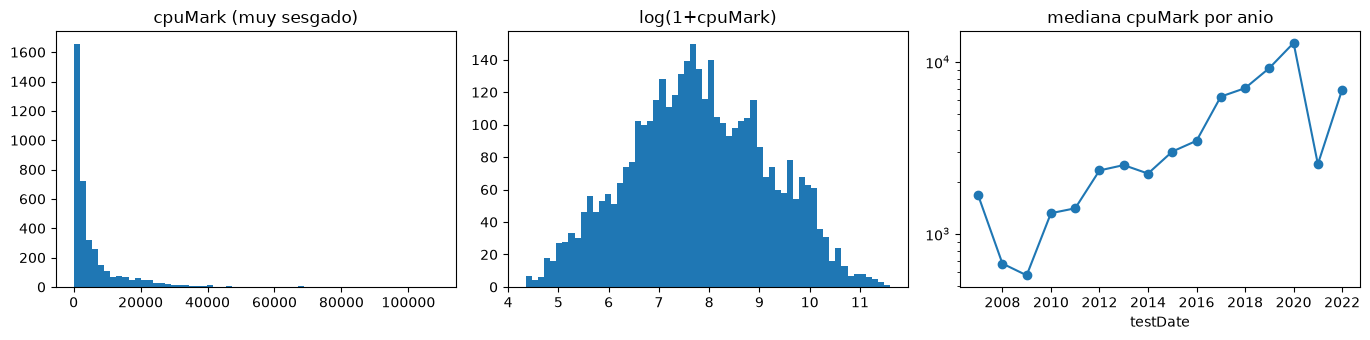

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].hist(df.cpuMark, 60); ax[0].set_title("cpuMark (muy sesgado)")
ax[1].hist(np.log1p(df.cpuMark), 60); ax[1].set_title("log(1+cpuMark)")
df.groupby("testDate").cpuMark.median().plot(ax=ax[2], marker="o"); ax[2].set_title("mediana cpuMark por anio"); ax[2].set_yscale("log")
plt.tight_layout(); plt.show()

El objetivo esta musho mas bonito en log, por eso entreno con log1p y regreso con expm1 (TransformedTargetRegressor). Tmb se ve que cada anio salen procesadores mas rapidos, eso va a ser el drift.

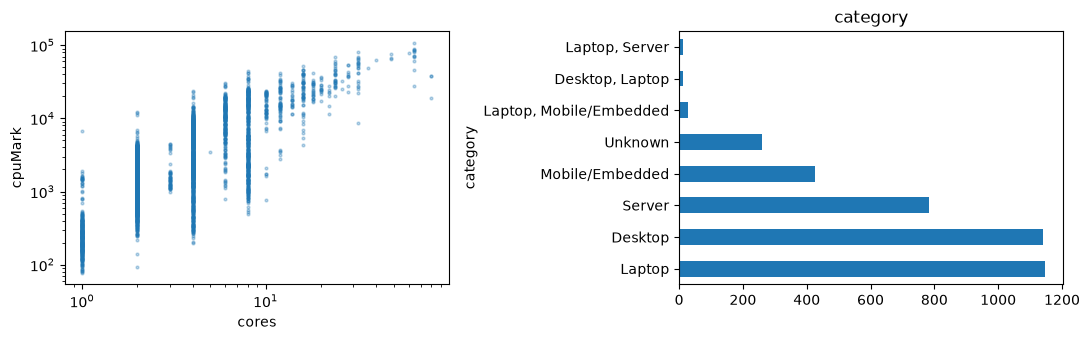

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].scatter(df.cores, df.cpuMark, s=4, alpha=.3); ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("cores"); ax[0].set_ylabel("cpuMark")
df.category.value_counts().head(8).plot.barh(ax=ax[1]); ax[1].set_title("category")
plt.tight_layout(); plt.show()

Ojo con 2 cosas que encontre:
- el csv viene **ordenado por cpuMark**, entonces un KFold sin revolver da resultados horribles (el stacking me dio R2 negativo por eso). Siempre uso `KFold(shuffle=True)`.
- `cpuValue`, `threadValue`, `powerPerf`, `threadMark` y `price` no se usan, osea se calculan con el benchmark o son otro benchmark (leakage).

## Paso 4 - variables y datos externos
`datos.preparar()` arma las variables: cores, TDP, anio, ghz que viene en el nombre, fabricante, familia, socket, banderas de tipo, y del nombre del modelo saco generacion, gama (i3/i5/i7/i9, ryzen 3/5/7/9) y sufijo (K, U, H, X...).

Como el dataset trae pocas columnas busque otros datasets para completar specs y los uno por nombre normalizado:
- TechPowerUp (kaggle `baraazaid/cpu-and-gpu-stats`): proceso en nm, cache L3, frecuencias
- pc_build (Hugging Face `mehax/pc_build`): hilos, base/boost, L2/L3, litografia

In [8]:
X, d = datos.preparar(df, externos=True)
y = df[config.OBJETIVO]
from src import externos
_, cob = externos.unir(df)
print("cobertura de los externos:", {k: (round(v, 2) if isinstance(v, float) else v) for k, v in cob.items()})
X.head()

cobertura de los externos: {'tpu': 0.32, 'pc_build': 0.09, 'cualquiera': 0.38, 'l3_mb': 0.28, 'proceso_nm': 0.38, 'base_ghz': 0.69, 'turbo_ghz': 0.38, 'hilos': 0.09, 'version_tpu': '2', 'version_pc_build': 'hf-main'}


,cores,TDP,anio,ghz_nombre,fabricante,familia,socket,es_desktop,es_laptop,es_server,es_mobile,generacion,gama,sufijo,l3_mb,proceso_nm,base_ghz,turbo_ghz,hilos
0,64,280.0,2022,NaN,AMD,Threadripper,sWRX8,1,0,0,0,5.0,0.995,W,256.0,7.0,2.70,4.500,NaN
1,64,280.0,2021,NaN,AMD,EPYC,SP3,0,0,1,0,NaN,NaN,ninguno,256.0,7.0,2.45,3.500,NaN
2,64,NaN,2021,NaN,AMD,EPYC,unknown,0,0,1,0,NaN,NaN,ninguno,NaN,NaN,NaN,NaN,NaN
3,64,225.0,2021,NaN,AMD,EPYC,SP3,0,0,1,0,NaN,NaN,ninguno,256.0,7.0,2.00,3.675,NaN
4,64,280.0,2020,NaN,AMD,Threadripper,sWRX8,1,0,0,0,3.0,0.995,W,256.0,7.0,2.70,4.200,NaN


Nomas ~38% de los procesadores hacen match, pero el imputer pone la mediana y un indicador de 'falta', asi no se pierde nada.

## Paso 5 - experimentos
Los experimentos estan en `src/experimentos.py` (`python -m src.experimentos`), cada variante es un run en el experimento `cpu-perf/experimentos` de mlflow con tags de experimento/variante. Aca nomas leo los resultados. Todo es MAE con KFold(5) revuelto salvo donde dice temporal.

In [9]:
exp = pd.read_csv("reportes/experimentos.csv")
cols = ["variante", "mae", "r2_log", "kpi_dentro_20pct"]
def ver(e):
    t = exp[exp.experimento == e][cols].copy()
    t["kpi_dentro_20pct"] = (t["kpi_dentro_20pct"] * 100).round(1)
    print(t.round(3).to_string(index=False))
exp.experimento.unique()

<ArrowStringArray>
[  'E2_variables',      'E3_socket',     'E4_modelos', 'E5_aumentacion',  'E6_validacion',       'E7_drift',  'E8_combinador',    'E1_objetivo',
    'E9_temporal',      'E10_smogn',    'E11_hibrido']
Length: 11, dtype: str

### Experimento 1 - objetivo original vs log

In [10]:
ver("E1_objetivo")

                      variante      mae  r2_log  kpi_dentro_20pct
        ridge cpuMark original 2732.809  -2.743              30.2
          ridge log(1+cpuMark) 1416.824   0.917              54.8
random_forest cpuMark original  806.328   0.949              72.7
  random_forest log(1+cpuMark)  807.561   0.954              73.3


Para ridge el log es esencial (2733 -> 1417). Para el RF casi da igual en MAE pero mejora R2 log y el KPI. **gana log, me quedo con log** para todos.

### Experimento 2 - que variables sirven (solo cores vs specs vs nombre vs externos)

In [11]:
ver("E2_variables")

                           variante      mae  r2_log  kpi_dentro_20pct
           solo cores (Actividad 3) 2940.848   0.649              18.9
             specs de hoja de datos  888.366   0.951              70.9
+ generacion/gama/sufijo del nombre  847.190   0.953              71.6
 + externos (cache, nm, GHz, hilos)  827.632   0.954              72.7


Solo con cores (como en la actividad 3) el MAE es 2941, con las specs baja a 888, lo del nombre (generacion/gama/sufijo) baja a 847 y los externos a 828. **gana todo junto, me quedo con specs + nombre + externos.**

### Experimento 3 - socket: target encoding vs one-hot vs sin socket

In [12]:
ver("E3_socket")

                     variante      mae  r2_log  kpi_dentro_20pct
        ridge target encoding 1557.954   0.909              50.2
random_forest target encoding  826.712   0.954              72.6
                ridge one-hot 1428.907   0.917              54.8
        random_forest one-hot  807.462   0.954              73.1
             ridge sin socket 1552.382   0.903              49.2
     random_forest sin socket  799.795   0.953              72.7


One-hot le gana a target encoding en los 2 modelos. Sin socket el RF sale un poquito mejor pero ridge empeora, entonces **gana one-hot (con min_frequency=10), me quedo con one-hot.**

### Experimento 4 - modelos de las diapositivas

In [13]:
ver("E4_modelos")

     variante      mae  r2_log  kpi_dentro_20pct
       lineal 1557.519   0.909              50.0
   polinomial 1207.482   0.925              59.9
        ridge 1557.954   0.909              50.2
        lasso 4395.828   0.334              15.5
          knn 1162.923   0.922              61.5
random_forest  826.712   0.954              72.6
          hgb  868.828   0.956              70.1
     stacking  821.872   0.956              71.9


Lasso con alpha default no sirve (despues en el pipeline con GridSearch si queda bien). Los arboles le ganan a los lineales por musho. **gana stacking por poquito sobre RF.**

### Experimento 5 - aumentacion de datos: SMOTER vs ruido gaussiano
Como son poquitos datos (3825) y en la gama alta hay muy pocos procesadores probe generar datos sinteticos:
- SMOTER (Torgo et al. 2013): como SMOTE pero para regresion, interpola entre vecinos de la zona rara (cpuMark alto)
- ruido gaussiano: copia los datos con 5% de ruido en las numericas

(esto no viene en las diapositivas, lo saque de papers)

In [14]:
ver("E5_aumentacion")

                  variante     mae  r2_log  kpi_dentro_20pct
              sin aumentar 827.632   0.954              72.7
SMOTER gama alta (p85, x1) 825.075   0.952              73.3
SMOTER gama alta (p70, x2) 844.760   0.952              72.5
        ruido gaussiano 5% 807.796   0.953              74.3


**gana ruido gaussiano (828 -> 808), me quedo con ruido** -> es el modelo `random_forest_ruido` del catalogo.

### Experimento 6 - validacion: kfold aleatorio vs temporal

In [15]:
ver("E6_validacion")

                             variante      mae  r2_log  kpi_dentro_20pct
                      kfold aleatorio  827.632   0.954              72.7
temporal (train <= 2019, test > 2019) 5156.596   0.564              21.1


Aqui esta lo mas importante del proyecto: con kfold aleatorio el MAE es 828 pero si entreno con <=2019 y pruebo con >2019 sube a ~5000. Osea el kfold es muy optimista porque mezcla procesadores del mismo anio/familia.
Como el caso de uso real es predecir procesadores **nuevos**, el modelo de produccion se escoge con `temporal_mae`, no con el kfold.

### Experimento 7 - drift: todo el pasado vs ventana vs pesos por antiguedad (temporal)

In [16]:
ver("E7_drift")

                                 variante      mae  r2_log  kpi_dentro_20pct
                           todo el pasado 4166.784   0.545              22.0
                  ventana ultimos 5 anios 4167.772   0.514              21.2
                  ventana ultimos 3 anios 4491.218   0.384              20.1
pesos por antiguedad (vida media 3 anios) 3931.467   0.589              22.0


Dar mas peso a lo reciente (vida media 3 anios) le gana a usar todo o solo una ventana. **gana pesos por antiguedad.**

### Experimento 8 - como combinar modelos: promedio vs Ensemble Selection (Caruana 2004)
Ensemble Selection va agregando (con reemplazo) el modelo que mas baja el error del ensamble, los pesos salen de cuantas veces lo escogio.

In [17]:
ver("E8_combinador")

                    variante      mae  r2_log  kpi_dentro_20pct
                  solo ridge 1557.954   0.909              50.2
                    solo knn 1162.923   0.922              61.5
          solo random_forest  826.712   0.954              72.6
                    solo hgb  868.828   0.956              70.1
    promedio simple (en log)  845.329   0.943              69.7
Ensemble Selection (Caruana)  838.949   0.954              72.9


In [18]:
r = mlflow.search_runs(experiment_names=["cpu-perf/experimentos"], filter_string="tags.variante = 'Ensemble Selection (Caruana)'")
print(r.filter(like="params.peso").iloc[0])

params.peso_hgb              0.24
params.peso_knn              0.12
params.peso_ridge             0.0
params.peso_random_forest    0.64
Name: 0, dtype: str


Caruana le gana al promedio simple pero no al RF solo (839 vs 827). Le da casi todo el peso al RF y nada a ridge. **gana RF solo** en kfold.

### Experimento 9 - los modelos en validacion temporal

In [19]:
ver("E9_temporal")

           variante      mae  r2_log  kpi_dentro_20pct
              ridge 4423.142   0.670              25.8
                knn 4254.440   0.748              23.4
      random_forest 4270.149   0.552              24.3
random_forest_ruido 3852.144   0.629              26.9
                hgb 3921.102   0.605              28.6
            hibrido 3259.734   0.738              31.8
           stacking 3901.356   0.649              25.0


Aqui cambia todo: en temporal el que gana es el **hibrido** (Ridge para la tendencia + RF sobre los residuos). El RF solo no puede extrapolar, nunca predice mas que lo maximo que vio en train, y ridge si sigue la tendencia de que todo crece cada anio.
**gana hibrido (3260 vs 3852 del siguiente), me quedo con hibrido para produccion.**

### Experimento 10 - SMOGN vs SMOTER vs ruido

In [20]:
ver("E10_smogn")

          variante     mae  r2_log  kpi_dentro_20pct
      sin aumentar 807.561   0.954              73.3
        SMOTER p85 799.944   0.953              73.8
         SMOGN p85 801.604   0.953              73.5
ruido gaussiano 5% 798.238   0.955              74.1


SMOGN (Branco 2017) es SMOTER + ruido gaussiano. Los 3 ayudan poquito y salen casi igual, **gana ruido gaussiano por poquito, me quedo con ruido** que es el mas simple.

### Experimento 11 - hibrido normal vs hibrido con pesos por antiguedad vs hibrido + ruido (temporal)
Junte lo que gano antes: el hibrido (E9) con los pesos por antiguedad (E7) y con el ruido (E5). Peso de cada procesador = 0.5^((anio_max - anio)/vida_media).

In [21]:
ver("E11_hibrido")

                    variante      mae  r2_log  kpi_dentro_20pct
                     hibrido 3259.734   0.738              31.8
  hibrido vida media 5 anios 2927.730   0.759              33.9
  hibrido vida media 3 anios 2943.951   0.771              32.3
  hibrido vida media 2 anios 3094.322   0.759              30.2
             hibrido + ruido 3189.260   0.745              30.8
hibrido vida media 3 + ruido 3164.406   0.743              28.9


Los pesos ayudan musho (3260 -> 2928 con vida media 5), el ruido aqui casi no hace nada y combinado con los pesos hasta empeora. **gana hibrido con vida media 5, me quedo con ese** y lo meti al catalogo como `hibrido_reciente`.
El GridSearch es con kfold revuelto y ahi no se ve el drift, por eso lo puse como otro modelo y que la validacion temporal decida.

## Paso 6 - entrenamiento final en mlflow
`python -m src.pipeline` entrena todo el catalogo con GridSearchCV. Cada modelo es un run hijo dentro de un run padre `entrenamiento__data-v26__fecha`, con tags de data_version, data_hash, objetivo, versiones de los externos, etc.

In [22]:
runs = mlflow.search_runs(experiment_names=[config.EXP_MULTI], filter_string="tags.data_version = '26' and tags.modelo != ''",
                          order_by=["start_time DESC"])
ult = runs[runs["tags.mlflow.parentRunId"] == runs["tags.mlflow.parentRunId"].iloc[0]]
t = ult[["tags.modelo", "metrics.mae", "metrics.r2_log", "metrics.kpi_dentro_20pct", "metrics.temporal_mae", "metrics.temporal_kpi_dentro_20pct"]]
t.columns = ["modelo", "kfold_mae", "kfold_r2log", "kfold_dentro20", "temporal_mae", "temporal_dentro20"]
t.sort_values("temporal_mae").round(3)

,modelo,kfold_mae,kfold_r2log,kfold_dentro20,temporal_mae,temporal_dentro20
1,hibrido_reciente,804.149,0.943,0.719,2784.363,0.359
2,hibrido,834.690,0.945,0.733,3174.746,0.332
3,random_forest_ruido,790.682,0.954,0.748,3852.144,0.269
0,stacking,820.571,0.950,0.716,3901.356,0.250
4,hgb,880.053,0.951,0.693,3921.102,0.286
6,knn,1086.094,0.902,0.671,3977.681,0.277
5,random_forest,805.446,0.954,0.735,4270.149,0.243
10,lineal,1422.937,0.917,0.546,4389.546,0.238
8,ridge,1416.824,0.917,0.548,4423.142,0.258
9,polinomial,1118.544,0.926,0.616,4762.362,0.281


En kfold el mejor es rf_ruido (791) pero en temporal gana `hibrido_reciente` (2784 y 36% dentro de +-20%), y en kfold tampoco queda mal (804). Como se escoge por temporal_mae es el campeon.

In [23]:
for v in cliente.search_model_versions(f"name='{config.MODELO_REGISTRADO}'"):
    print(f"version {v.version} | modelo {v.tags.get('modelo')} | data v{v.tags.get('data_version')} | temporal_mae {v.tags.get('temporal_mae')}")
prod = cliente.get_model_version_by_alias(config.MODELO_REGISTRADO, config.ALIAS_PRODUCCION)
print(); print(f"alias '{config.ALIAS_PRODUCCION}' -> version {prod.version} ({prod.tags.get('modelo')})")

version 3 | modelo hibrido_reciente | data v26 | temporal_mae 2784.4
version 2 | modelo hibrido | data v26 | temporal_mae 3174.7
version 1 | modelo stacking | data v26 | temporal_mae None



alias 'produccion' -> version 3 (hibrido_reciente)


El alias `produccion` apunta a la version que se sirve. Solo se mueve si la nueva version mejora el temporal_mae de la actual, osea si un dia sale peor se registra pero no se promueve.

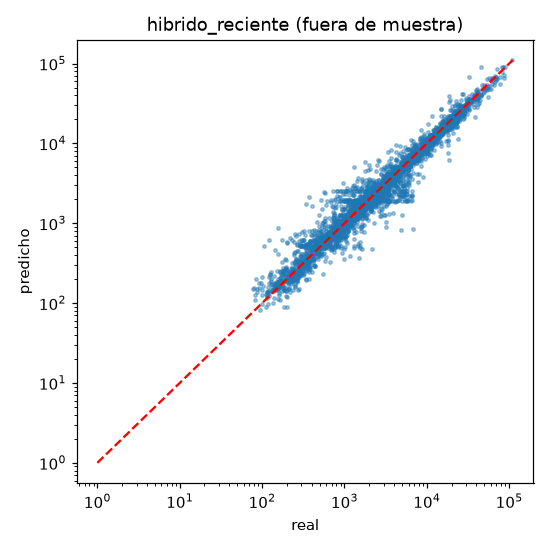

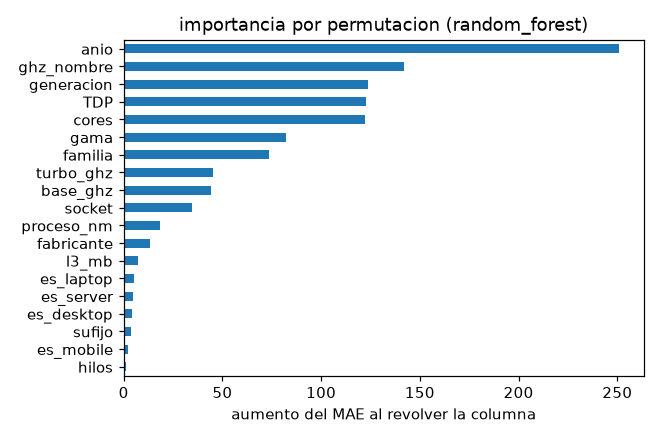

In [24]:
display(Image("reportes/pred_vs_real_hibrido_reciente.png", width=380)); display(Image("reportes/importancia_permutacion.png", width=520))

Lo que mas pesa por mucho son los cores, luego el anio y el TDP.

## Paso 7 - preguntas del proyecto
Esto sale de `python -m src.analisis` (experimento `cpu-perf/analisis`).

**Escala con los nucleos? (Amdahl)**: regresion de log(cpuMark) contra log(cores). Si escalara perfecto la elasticidad seria 1.

                segmento    n  elasticidad_cores  curvatura
                   todos 3825              1.402     -0.146
                 desktop 1166              1.699     -0.175
                  laptop 1200              2.004     -0.129
                  server  805              1.273     -0.174
todos (controlando anio) 3825              1.269        NaN


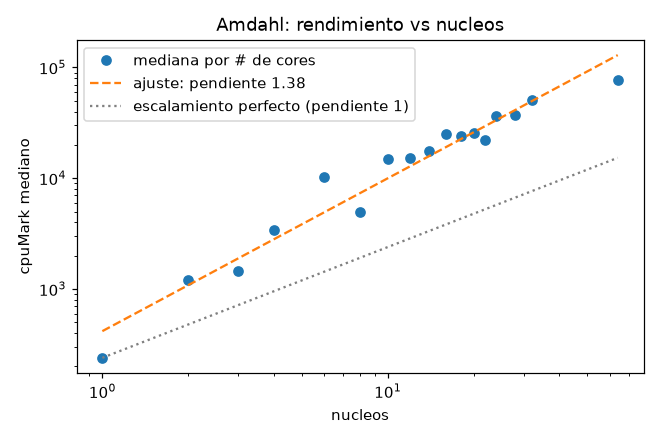

In [25]:
print(pd.read_csv("reportes/amdahl.csv").round(3).to_string(index=False))
display(Image("reportes/amdahl.png", width=520))

La elasticidad sale >1 porque los procesadores con mas nucleos tmb son mas nuevos. Controlando por anio baja a 1.27, y la curvatura negativa indica que cada vez rinde menos agregar nucleos, algo como Amdahl.

**Nucleos vs frecuencia**: con Cinebench R23 (dataset con frecuencia turbo y hilos) y la misma regresion en log:

In [26]:
print(json.dumps(json.load(open("reportes/nucleos_vs_frecuencia.json")), indent=2))

{
  "multiScore": {
    "log_cores": 0.897,
    "log_turbo": 0.781,
    "log_hilos_por_core": 0.315,
    "r2": 0.854
  },
  "singleScore": {
    "log_cores": 0.015,
    "log_turbo": 0.951,
    "log_hilos_por_core": -0.182,
    "r2": 0.325
  }
}


En multi-core los cores pesan 0.90 y la frecuencia 0.78. En single-core los cores casi no importan (0.015) y la frecuencia casi todo (0.95), que es lo que uno esperaria.

**Que pesa en single-core vs multi-core** (importancia por permutacion con el mismo modelo):

            cpuMark  threadMark
cores         0.607       0.129
anio          0.143       0.285
TDP           0.080       0.126
familia       0.047       0.076
proceso_nm    0.037       0.007
l3_mb         0.015       0.003
gama          0.015       0.048
socket        0.013       0.017


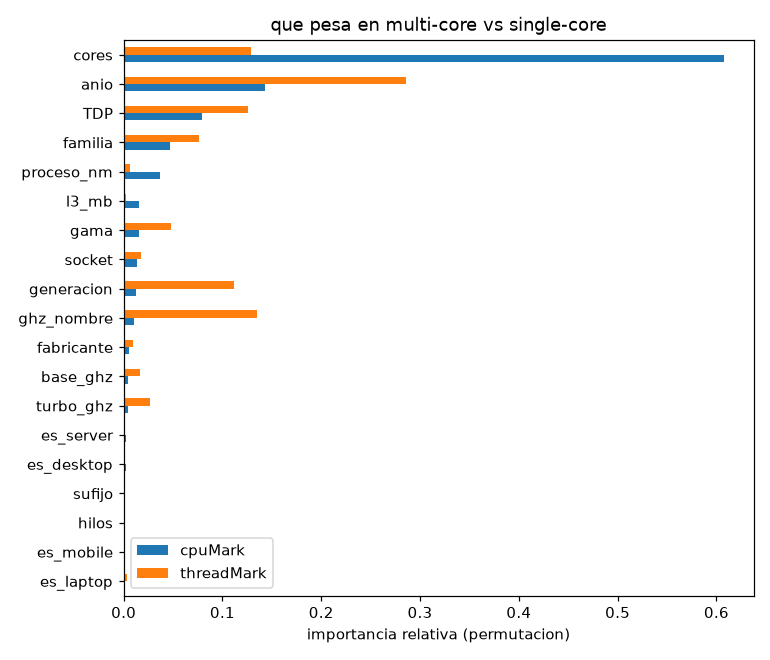

In [27]:
print(pd.read_csv("reportes/single_vs_multi.csv", index_col=0).sort_values("cpuMark", ascending=False).round(3).head(8))
display(Image("reportes/single_vs_multi.png", width=520))

**Procesadores que rinden mas o menos de lo esperado** (real / predicho fuera de muestra):

In [28]:
s = pd.read_csv("reportes/sobre_y_bajo_rendimiento.csv")
print(s.head(6).to_string(index=False)); print("..."); print(s.tail(6).to_string(index=False))

                               cpu  real  esperado  ratio
           Intel Pentium Gold 8505  6771     375.0  18.07
       ARM Cortex-A72 4 Core 0 MHz  4907     457.0  10.74
      ARM Neoverse-N1 4 Core 0 MHz  3176     441.0   7.20
                         AMD 4700S 18224    2759.0   6.60
Intel Xeon Platinum 8151 @ 3.40GHz  6591    1168.0   5.64
    Intel Core i3-11100B @ 3.60GHz 11357    2507.0   4.53
...
                               cpu  real  esperado  ratio
                         msm8960dt   252    1060.0   0.24
           Intel Pentium 4 3.83GHz   154     652.0   0.24
Qualcomm Technologies, Inc MSM8929   560    2389.0   0.23
    Intel Core i7-2630UM @ 1.60GHz   400    1904.0   0.21
                     Intel 2.80GHz   341    1689.0   0.20
       ARM Cortex-A53 4 Core 0 MHz   374    2533.0   0.15


Los que rinden de mas suelen ser ARM/servidor o con datos raros (0 MHz, nombres genericos). Los que rinden de menos son chips viejos o moviles donde el TDP/cores no dice mucho.

## Paso 8 - drift
`python -m src.drift`: comparo procesadores <=2019 (referencia) vs >2019 (nuevos)
- **data drift**: PSI y KS en cada entrada
- **label drift**: PSI/KS en log(cpuMark)
- **concept drift**: el modelo entrenado con lo viejo, que tanto se equivoca en lo nuevo y si el error tiene sesgo por anio

In [29]:
print(pd.read_csv("reportes/data_drift.csv").round(3).to_string(index=False))

  variable       tipo   psi    nivel    ks  p_valor  media_ref  media_nuevos
fabricante categorica 3.201   fuerte   NaN    0.000        NaN           NaN
 es_mobile categorica 2.107   fuerte   NaN    0.000        NaN           NaN
     cores   numerica 1.585   fuerte 0.456    0.000      3.940         8.234
   familia categorica 1.577   fuerte   NaN    0.000        NaN           NaN
       TDP   numerica 0.295   fuerte 0.142    0.000     59.756        76.207
 es_laptop categorica 0.226 moderado   NaN    0.000        NaN           NaN
es_desktop categorica 0.106 moderado   NaN    0.000        NaN           NaN
ghz_nombre   numerica 0.092  estable 0.066    0.137      2.442         2.514
 es_server categorica 0.058  estable   NaN    0.000        NaN           NaN


In [30]:
r = json.load(open("reportes/drift_resumen.json"))
print("label drift :", {k: round(v, 3) for k, v in r["label_drift"].items()})
print("concept drift:", {k: round(v, 3) for k, v in r["concept_drift"].items()})

label drift : {'psi': 0.491, 'ks': 0.267, 'p_valor': 0.0, 'mediana_ref': 2003.0, 'mediana_nuevos': 4396.0}
concept drift: {'mae_viejos': 530.492, 'mae_nuevos': 3921.102, 'r2_log_viejos': 0.97, 'r2_log_nuevos': 0.605, 'dentro20_viejos': 0.77, 'dentro20_nuevos': 0.286, 'sesgo_log_medio_nuevos': -0.367, 'factor_subestimacion': 0.693}


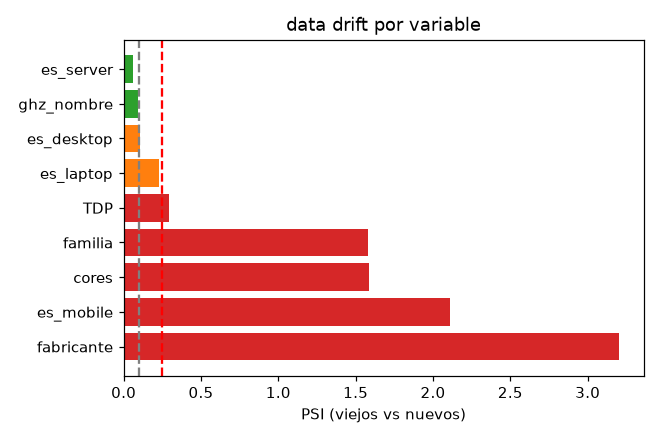

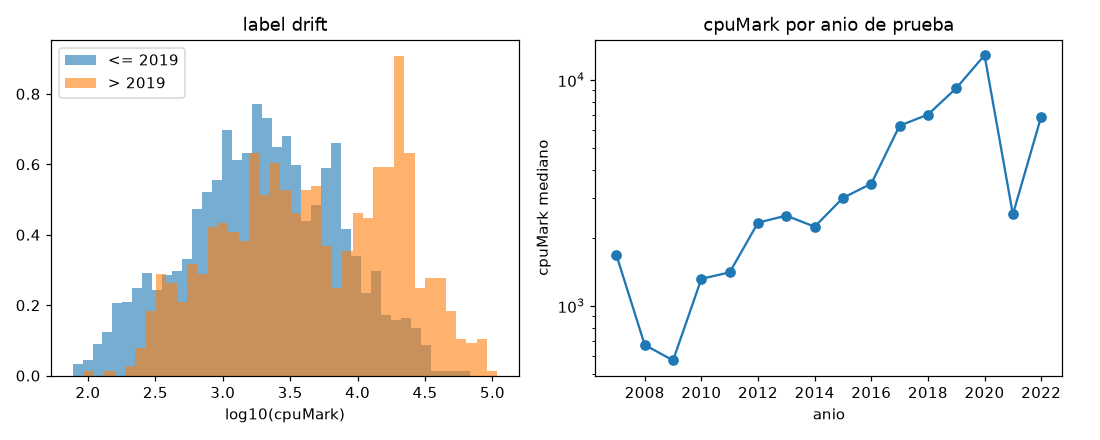

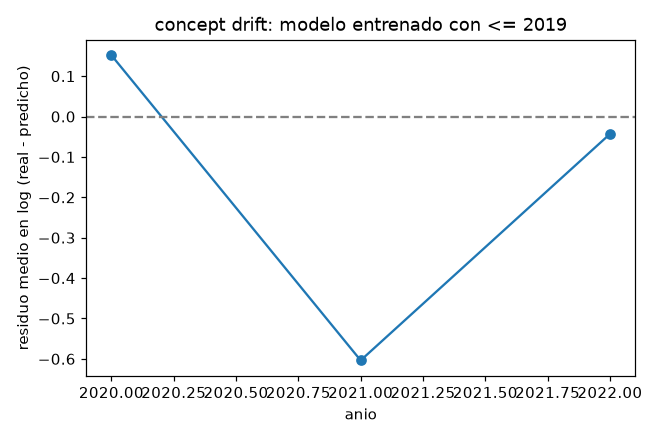

In [31]:
display(Image("reportes/drift_entradas.png", width=700)); display(Image("reportes/drift_label.png", width=420)); display(Image("reportes/drift_concepto.png", width=520))

Hay de los 3 tipos:
- data drift fuerte en fabricante, es_mobile, cores (la media pasa de ~3.9 a ~8.2), familia y TDP. Entraron muchos chips moviles ARM (MediaTek, Qualcomm...) que antes casi no habia
- label drift: la mediana de cpuMark pasa de 2003 a 4396 (PSI 0.49)
- concept drift: el modelo viejo tiene MAE 530 en lo viejo y 3921 en lo nuevo, y en promedio predice ~0.69 de lo real. La misma spec (ej. 16 cores, 125W) rinde mas en 2022 que en 2018, osea la relacion X -> y cambio

## Paso 9 - simulacion de produccion anio por anio
Para ver si el monitoreo sirve de algo simule que cada anio llega una version nueva del dataset (`python -m src.simulacion`). Arranca con un modelo entrenado con datos hasta 2013 y comparo 3 estrategias:
- **congelado**: nunca se reentrena
- **cada anio**: se reentrena siempre
- **por alerta**: solo se reentrena si el KPI cae >10 puntos vs lo esperado o si hay PSI > 0.25 contra los ultimos 2 anios que vio el modelo

Cada anio es un run en `cpu-perf/simulacion` y cada reentrenamiento una version nueva del modelo `cpu-perf-simulacion` con tag de la razon.

 anio  n_nuevos  dentro20_congelado  dentro20_anual  dentro20_alerta   decision                                         razon
 2014       280                0.60            0.60             0.60   mantener                                              
 2015       190                0.50            0.53             0.50   mantener                                              
 2016       183                0.43            0.54             0.43   mantener                                              
 2017       203                0.43            0.59             0.43   mantener                                              
 2018       173                0.35            0.63             0.35 reentrenar                               KPI cae 18% pts
 2019       216                0.31            0.67             0.67   mantener                                              
 2020       205                0.26            0.62             0.56   mantener                                       

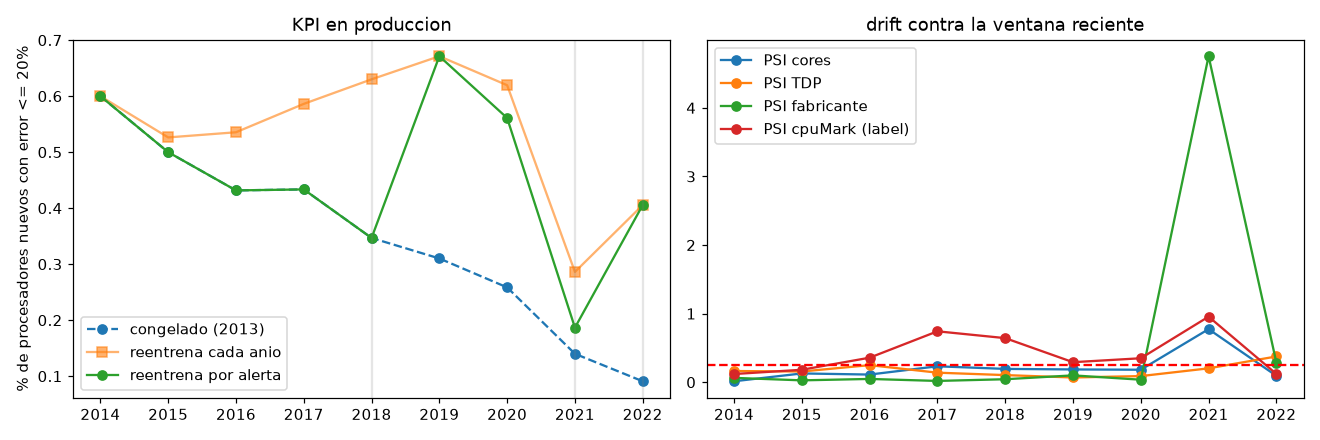

In [32]:
sim = pd.read_csv("reportes/simulacion.csv")
print(sim[["anio", "n_nuevos", "dentro20_congelado", "dentro20_anual", "dentro20_alerta", "decision", "razon"]].round(2).fillna("").to_string(index=False))
print(json.dumps({k: round(v, 3) for k, v in json.load(open("reportes/simulacion_resumen.json")).items()}, indent=2))
display(Image("reportes/simulacion.png", width=800))

(el modelo es el mismo tipo que gano, hibrido con vida media 5)

El congelado se cae de 60% a 9% de procesadores dentro de +-20%. Reentrenar cada anio da 54% en promedio con 9 reentrenamientos y por alerta 46% con solo 3. Osea por alerta se ahorra 6 de 9 reentrenamientos y pierde unos 8 puntos, depende de cuanto cueste reentrenar. Aqui reentrenar es baratisimo (segundos) entonces yo lo dejaria cada vez que llegan datos nuevos (que es lo que hace el pipeline con el hash), y las alertas sirven para avisar.

Tmb probe la simulacion con un RF normal y el congelado se caia musho mas rapido (18% promedio vs 35% del hibrido), porque el RF no extrapola y el hibrido si sigue la tendencia con la parte de ridge.

En 2021 todos se caen porque entraron 643 procesadores, muchos moviles ARM, que el modelo casi no habia visto.

## Paso 10 - como llevar la prediccion: batch y online
- **batch** (`python -m src.batch entrada.csv salida.csv`): para catalogos o cuando sale una tanda de procesadores. Cada lote es un run en `cpu-perf/batch` con la version del modelo y el hash de la entrada; si el csv ya trae cpuMark real tmb se loggea el error real.
- **online** (`uvicorn src.servir:app`): API FastAPI con `/predict`, `/health` y `/metricas`, por ejemplo para una pagina que te diga cuanto rinde un procesador antes de comprarlo.
- **streaming**: no aplica, salen pocos procesadores por dia y no hay eventos en tiempo real.
- **edge**: tampoco, el modelo pesa poco pero no hay un dispositivo que necesite predecir sin red.

Pruebo la API sin levantar servidor con TestClient:

In [33]:
from fastapi.testclient import TestClient
from src.servir import app
with TestClient(app) as c:
    print(c.get("/health").json())
    r = c.post("/predict", json=[
        {"cpuName": "AMD Ryzen 9 5950X", "cores": 16, "TDP": 105, "testDate": 2021, "socket": "AM4", "category": "Desktop"},
        {"cpuName": "Intel Core i5-1135G7 @ 2.40GHz", "cores": 4, "TDP": 28, "testDate": 2021, "socket": "FCBGA1449", "category": "Laptop"},
        {"cpuName": "procesador inventado", "cores": 300, "TDP": None, "testDate": 2030, "category": "Server"}])
    print(json.dumps(r.json(), indent=2))

{'status': 'ok', 'modelo': 'cpu-perf-multicore', 'version': 3, 'alias': 'produccion', 'cargado_en': '2026-11-09T01:35:59'}
{
  "cpuMark_estimado": [
    52634,
    10732,
    360706
  ],
  "latencia_ms": 86.42,
  "modelo_version": 3,
  "alertas": [
    "cores: 1 fuera de rango [1, 256]",
    "TDP: 1 nulos",
    "testDate > 2022: el modelo no ha visto procesadores tan nuevos (posible drift)"
  ]
}


El 5950X tiene ~46000 en PassMark (y tmb estaba en train). El tercero es inventado para ver que salgan las alertas de calidad de datos.

In [34]:
lote = df[df.testDate >= 2022].drop(columns=config.COLUMNAS_LEAKAGE[:-1] + ["price"], errors="ignore").head(40)
lote.to_csv("datos/lote_ejemplo.csv", index=False)
from src.batch import predecir_lote
out, alertas = predecir_lote("datos/lote_ejemplo.csv", "reportes/lote_ejemplo_pred.csv")
print("alertas:", alertas)
out[["cpuName", "cores", "TDP", "cpuMark", "cpuMark_estimado"]].head(10)

alertas: ['TDP: 1 nulos']


,cpuName,cores,TDP,cpuMark,cpuMark_estimado
0,AMD Ryzen Threadripper PRO 5995WX,64,280.0,108822,103520.0
1,AMD Ryzen Threadripper PRO 5975WX,32,280.0,80842,79622.0
2,AMD Ryzen Threadripper PRO 5965WX,24,280.0,68405,69901.0
3,AMD Ryzen Threadripper PRO 5955WX,16,280.0,51656,51742.0
4,Intel Xeon Platinum 8347C @ 2.10GHz,36,210.0,49386,50310.0
5,AMD EPYC 7713P,64,225.0,45860,73879.0
6,Intel Core i9-12900KS,8,150.0,44243,39882.0
7,AMD Ryzen Threadripper PRO 5945WX,12,280.0,41578,39199.0
8,Apple M1 Ultra 20 Core,16,60.0,41360,39744.0
9,Intel Xeon W-3335 @ 3.40GHz,16,250.0,38944,37933.0


Ojo: estos procesadores si estaban en el entrenamiento del modelo de produccion (se entrena con todo), por eso salen tan cerca. El error real en procesadores nuevos es el de la validacion temporal.

## Paso 11 - observabilidad
Cada prediccion (batch u online) se guarda en `monitoreo.db` (sqlite) con latencia, version del modelo, entrada, salida y alertas.
- **latencia y salud**: p50/p95, tasa de error, `/health` dice que version esta cargada
- **data quality**: alertas de rangos, nulos y anios que el modelo no ha visto
- **performance**: cuando llegan los benchmarks reales (batch con cpuMark) se loggea MAE real
- **business KPI**: % de procesadores con error <= 20%

In [35]:
print(json.dumps(monitoreo.resumen(), indent=2))

{
  "n_peticiones": 58,
  "n_procesadores": 773,
  "latencia_p50_ms": 62.377158499657526,
  "latencia_p95_ms": 243.11762144907323,
  "tasa_error": 0.0,
  "pct_peticiones_con_alertas": 0.3103448275862069,
  "por_modo": {
    "online": 48,
    "batch": 10
  },
  "versiones_modelo": {
    "2": 29,
    "1": 22,
    "3": 7
  }
}


## Paso 12 - mlflow es queryable
Los metadatos viven en `mlflow.db` (sqlite) y los artifacts (modelos, graficas, csv) en `mlartifacts/`. Se puede preguntar con la api de mlflow o directo con SQL.

In [36]:
# los 5 mejores runs en temporal de todos los entrenamientos con la data v26
mlflow.search_runs(experiment_names=[config.EXP_MULTI], filter_string="tags.data_version = '26' and metrics.temporal_mae < 4000",
                   order_by=["metrics.temporal_mae ASC"], max_results=5)[["tags.mlflow.runName", "metrics.temporal_mae", "metrics.mae", "tags.data_hash"]]

,tags.mlflow.runName,metrics.temporal_mae,metrics.mae,tags.data_hash
0,hibrido_reciente__data-v26,2784.362986,804.148884,ecc4a219587e
1,hibrido__data-v26,3174.745558,834.690091,ecc4a219587e
2,hibrido__data-v26,3174.745558,834.690091,ecc4a219587e
3,random_forest_ruido__data-v26,3852.143637,790.681858,ecc4a219587e
4,random_forest_ruido__data-v26,3852.143637,790.681858,ecc4a219587e


In [37]:
con = sqlite3.connect(config.MLFLOW_DB)
print(pd.read_sql('''
select e.name as experimento, count(r.run_uuid) as runs
from experiments e left join runs r on r.experiment_id = e.experiment_id
group by e.name order by runs desc''', con).to_string(index=False))

          experimento  runs
cpu-perf/experimentos    72
  cpu-perf/simulacion    33
  cpu-perf/multi-core    32
 cpu-perf/single-core    12
       cpu-perf/batch    10
       cpu-perf/drift     3
    cpu-perf/analisis     1
              Default     0


In [38]:
pd.read_sql('''
select r.name as run, m.value as temporal_mae, t.value as data_version, r.artifact_uri
from runs r
join metrics m on m.run_uuid = r.run_uuid and m.key = 'temporal_mae'
join tags t on t.run_uuid = r.run_uuid and t.key = 'data_version'
join experiments e on e.experiment_id = r.experiment_id and e.name = 'cpu-perf/multi-core'
order by m.value limit 5''', con)

,run,temporal_mae,data_version,artifact_uri
0,hibrido_reciente__data-v26,2784.362986,26,file:///mnt/c/Users/EliasRodriguez/Documents/G...
1,hibrido__data-v26,3174.745558,26,file:///mnt/c/Users/EliasRodriguez/Documents/G...
2,hibrido__data-v26,3174.745558,26,file:///mnt/c/Users/EliasRodriguez/Documents/G...
3,random_forest_ruido__data-v26,3852.143637,26,file:///mnt/c/Users/EliasRodriguez/Documents/G...
4,random_forest_ruido__data-v26,3852.143637,26,file:///mnt/c/Users/EliasRodriguez/Documents/G...


La ultima columna muestra que el sqlite nomas guarda la ruta, el modelo en si esta en la carpeta de artifacts.

## Paso 13 - automatizacion
`correr_pipeline.sh` corre `python -m src.pipeline` y se puede poner en cron (ej. cada lunes):
```
0 6 * * 1 /ruta/Proj/correr_pipeline.sh
```
Pasos del pipeline: bajar datos -> si el hash es igual no hace nada -> calidad (si falla se detiene) -> externos -> entrenar y promover -> single-core -> drift -> batch con los procesadores mas nuevos -> `reportes/ultimo_pipeline.json`.

Para ver todo en la UI: `mlflow ui --backend-store-uri sqlite:///mlflow.db` (desde Proj).

## Resumen
- con specs + nombre + externos el RF llega a MAE ~800 y R2 log 0.95 en kfold, contra 2941 que daba con solo cores
- pero en procesadores nuevos el error es ~4-5x, por drift. Por eso se escoge el modelo con validacion temporal: el hibrido (ridge + RF en residuos) con pesos por antiguedad, MAE temporal 2784 y 36% dentro de +-20% (el RF solo: 4270 y 24%)
- la aumentacion (ruido, SMOTER, SMOGN) ayuda poquito, los datos externos tmb
- sin reentrenar el modelo se vuelve inutil en unos anios (KPI 60% -> 9%), con el monitoreo se mantiene en ~45-55%